# A7: where and why the model is wrong on Thai patches

The models of part B score well on EuroSAT and worse on Thailand (`outputs/b/b9_table.md`). This notebook looks at the **wrong
predictions** on the Thai test patches to find out which mistakes the model makes, where they are, and what the wrong patches look like.

**What is analysed**
- Main model: ResNet-18 on 12 bands, trained on EuroSAT, seed 42, applied to the Thai **L1C** patches without any change ("zero-shot").
  The same model with **AdaBN** is used for comparison, and the seed 1 and seed 2 models to see whether a mistake repeats.
- Test patches: the 3,023 pure Thai patches with their WorldCover label, and the 199 hand-labelled patches of step A1.
- Nothing is trained or predicted here: the predictions are read from `outputs/predictions/` (made by `src/predict.py`).

**Keep in mind**
- The Thai images are a January-February median composite (dry season); every EuroSAT patch is a single date from any season.
- Each Thai class comes from one or two study areas, so a result stands for that area (see `DATA_NOTES.md`).
- Section 4 tests explanations with numbers. An explanation that fits the numbers is still a likely cause, not a proven one,
  because no image of the same places in another season was looked at.

Outputs go to `outputs/a7/`.

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score

import config as c

# colours on a light surface, as in A2 to A5
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CLASS_COLORS = {"forest": "#008300", "crop": "#e87ba4", "water": "#4a3aa7", "built-up": "#e34948", "grassland": "#eda100"}
RUN_COLORS = {"zero-shot": "#eb6834", "AdaBN": "#2a78d6"}
SOURCE_COLORS = {"EuroSAT (train)": "#2a78d6", "Thai L1C": "#eb6834"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.family": "sans-serif", "font.size": 10,
})

OUT = c.OUTPUT_DIR / "a7"
OUT.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    # Windows sometimes refuses to open a file that was written a moment ago, so retry a few times
    path = OUT / name
    for attempt in range(5):
        try:
            fig.savefig(path, dpi=130, bbox_inches="tight")
            break
        except OSError:
            if attempt == 4:
                raise
            time.sleep(1)
    print("saved", path)

## 1. Load the labels and the predictions

One row per pure Thai patch: study area, WorldCover label, and the prediction and confidence of every run. `zs` is the zero-shot run,
`adabn` the AdaBN run, `s1` and `s2` the zero-shot runs of the models trained with seed 1 and seed 2.

In [2]:
TH = pd.read_csv(c.PATCH_DIR / "thailand_patches.csv", keep_default_na=False)   # "nan" is an area name here
PRED = c.OUTPUT_DIR / "predictions"
RUNS = {"zs": "resnet18_12band_thai-L1C", "adabn": "resnet18_12band_thai-L1C_adabn",
        "s1": "resnet18_12band_seed1_thai-L1C", "s2": "resnet18_12band_seed2_thai-L1C"}

df = TH[TH["pure"]].set_index("patch_id")[["area", "label", "purity", "row", "col"]].copy()
for key, run in RUNS.items():
    p = pd.read_csv(PRED / f"predictions_{run}.csv").set_index("patch_id")
    df[key] = p.loc[df.index, "predicted_label"]
    df[f"{key}_conf"] = p.loc[df.index, "confidence"]
for key in RUNS:
    df[f"{key}_ok"] = df[key] == df["label"]
df["wrong_in_all_seeds"] = ~df["zs_ok"] & ~df["s1_ok"] & ~df["s2_ok"]

print(f"{len(df)} pure patches; zero-shot wrong: {(~df['zs_ok']).sum()}, AdaBN wrong: {(~df['adabn_ok']).sum()}")

3023 pure patches; zero-shot wrong: 891, AdaBN wrong: 645


## 2. Which mistakes, and in which study area

Every wrong prediction is a pair *true class -> predicted class*. The table counts the pairs for the zero-shot and the AdaBN run.

In [3]:
pairs = pd.concat({
    "zero-shot": df[~df["zs_ok"]].groupby(["label", "zs"]).size(),
    "AdaBN": df[~df["adabn_ok"]].groupby(["label", "adabn"]).size(),
}, axis=1).fillna(0).astype(int)
pairs.index.names = ["true class", "predicted"]
pairs = pairs.sort_values("zero-shot", ascending=False)
pairs["zero-shot, share of errors"] = (pairs["zero-shot"] / pairs["zero-shot"].sum()).round(3)
pairs.to_csv(OUT / "error_pairs.csv")
pairs

zero-shot  AdaBN  zero-shot, share of errors
true class predicted                                              
forest     grassland        618    484                       0.694
crop       grassland        132     59                       0.148
forest     crop              93     10                       0.104
crop       built-up          43     14                       0.048
           water              2     22                       0.002
forest     built-up           1      1                       0.001
crop       forest             1     32                       0.001
forest     water              1     14                       0.001
built-up   water              0      9                       0.000

In [4]:
by_area = df.groupby(["label", "area"]).agg(
    patches=("zs_ok", "size"),
    wrong_zero_shot=("zs_ok", lambda s: int((~s).sum())),
    wrong_adabn=("adabn_ok", lambda s: int((~s).sum())),
)
by_area["error_rate_zero_shot"] = (by_area["wrong_zero_shot"] / by_area["patches"]).round(3)
by_area["error_rate_adabn"] = (by_area["wrong_adabn"] / by_area["patches"]).round(3)
by_area.to_csv(OUT / "errors_by_class_and_area.csv")
by_area

patches  wrong_zero_shot  wrong_adabn  \
label    area                                                  
built-up bangkok           280                0            9   
         suphanburi          1                0            0   
crop     kanchanaburi        1                0            0   
         nan                13                9           10   
         suphanburi        521              169          117   
forest   bangkok             5                5            0   
         kanchanaburi     1088              388          286   
         nan               683              320          223   
water    kanchanaburi      431                0            0   

                       error_rate_zero_shot  error_rate_adabn  
label    area                                                  
built-up bangkok                      0.000             0.032  
         suphanburi                   0.000             0.000  
crop     kanchanaburi                 0.000             0.000  
         nan                          0.692             0.769  
         suphanburi                   0.324             0.225  
forest   bangkok                      1.000             0.000  
         kanchanaburi                 0.357             0.263  
         nan                          0.469             0.327  
water    kanchanaburi                 0.000             0.000

### Figure: the mistakes, zero-shot against AdaBN

Only pairs with at least 5 wrong patches in one of the two runs are drawn.

saved C:\Users\kanoo\Data_Mining_Project\outputs\a7\error_pairs.png


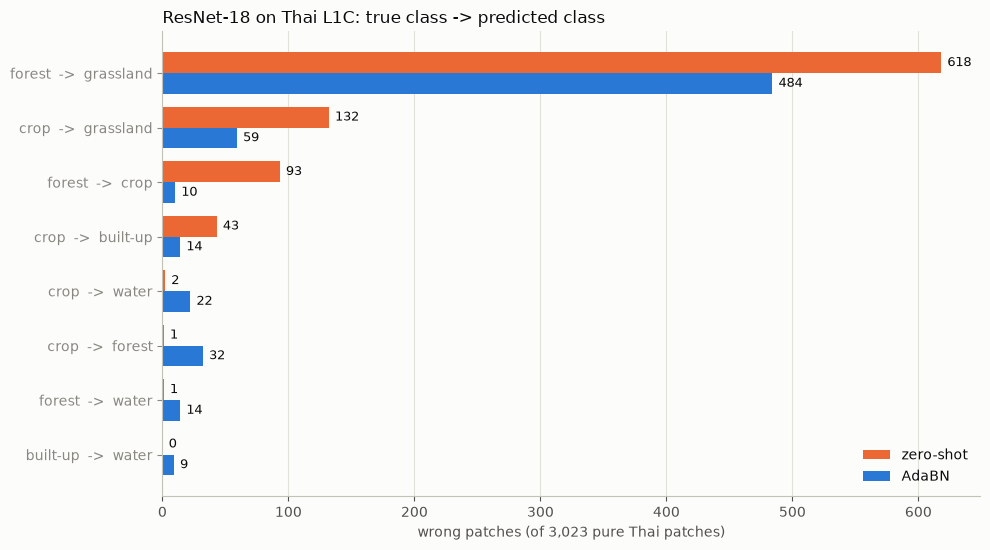

In [5]:
shown = pairs[(pairs["zero-shot"] >= 5) | (pairs["AdaBN"] >= 5)]
names = [f"{t}  ->  {p}" for t, p in shown.index]
y = np.arange(len(shown))
fig, ax = plt.subplots(figsize=(10, 0.55 * len(shown) + 1.2))
h = 0.38
for i, (run, col) in enumerate(RUN_COLORS.items()):
    values = shown[run].to_numpy()
    ax.barh(y + (i - 0.5) * h, values, height=h, color=col, label=run)
    for yy, v in zip(y + (i - 0.5) * h, values):
        ax.text(v + 5, yy, str(v), va="center", fontsize=9, color=INK)
ax.set_yticks(y)
ax.set_yticklabels(names)
ax.invert_yaxis()
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("wrong patches (of 3,023 pure Thai patches)")
ax.set_title("ResNet-18 on Thai L1C: true class -> predicted class", loc="left", fontsize=12, color=INK)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
save(fig, "error_pairs.png")
plt.show()

### What AdaBN changes

AdaBN re-estimates the batch-normalisation statistics on the Thai images. The table shows how many patches move between right and wrong.

In [6]:
moves = pd.crosstab(df["zs_ok"].map({True: "right", False: "wrong"}).rename("zero-shot"),
                    df["adabn_ok"].map({True: "right", False: "wrong"}).rename("AdaBN"))
print(moves, "\n")
fixed = df[~df["zs_ok"] & df["adabn_ok"]].groupby(["label", "zs"]).size().rename("fixed by AdaBN")
broken = df[df["zs_ok"] & ~df["adabn_ok"]].groupby(["label", "adabn"]).size().rename("new error with AdaBN")
print(fixed.to_string(), "\n")
print(broken.to_string())

AdaBN      right  wrong
zero-shot              
right       2057     75
wrong        321    570 

label   zs       
crop    built-up      24
        forest         1
        grassland     74
forest  built-up       1
        crop          25
        grassland    196 

label     adabn    
built-up  water         9
crop      built-up      2
          forest       22
          grassland    18
          water         6
forest    grassland    15
          water         3


## 3. What the wrong patches look like

For every main mistake three rows of patches, all in true colour (B4, B3, B2) with the same brightness scale:

1. Thai patches of the true class that the model got **wrong** (title: area and confidence),
2. Thai patches of the same class that the model got **right**, from the same study areas,
3. **EuroSAT** training patches of the class the model predicted, i.e. what the model learned that class looks like.

The patches are drawn at random (seed 42) from each group, not picked by hand, so they are typical of the group.

In [7]:
X_TH = np.load(c.PATCH_DIR / "thailand_X_L1C.npy", mmap_mode="r")      # the model input
X_EU = np.load(c.EUROSAT_DIR / "eurosat_X.npy", mmap_mode="r")
EU_Y10 = np.load(c.EUROSAT_DIR / "eurosat_y10.npy")
EU_SPLIT = np.load(c.EUROSAT_DIR / "eurosat_split.npy")
RGB = [c.BANDS.index(b) for b in ("B4", "B3", "B2")]
N = 8


def rgb(patch):
    return np.clip(np.asarray(patch, dtype="float32")[RGB].transpose(1, 2, 0) / 3000, 0, 1)


def eurosat_ids(original_classes, n, rng):
    """n training patches, shared evenly between the given original EuroSAT classes."""
    per = int(np.ceil(n / len(original_classes)))
    ids = []
    for name in original_classes:
        pool = np.flatnonzero((EU_Y10 == c.EUROSAT_CLASSES.index(name)) & (EU_SPLIT == 0))
        ids += [(i, name) for i in rng.choice(pool, per, replace=False)]
    return ids[:n]


def example_figure(true_cls, pred_cls, eu_classes, areas, name):
    rng = np.random.default_rng(c.SEED)
    in_areas = df["area"].isin(areas) & (df["label"] == true_cls)
    wrong = df[in_areas & (df["zs"] == pred_cls)]
    right = df[in_areas & df["zs_ok"]]
    wrong_ids = rng.choice(wrong.index, min(N, len(wrong)), replace=False)
    right_ids = rng.choice(right.index, min(N, len(right)), replace=False)
    eu = eurosat_ids(eu_classes, N, rng)

    fig, axes = plt.subplots(3, N, figsize=(2 * N, 7.2))
    rows = [
        (f"Thai {true_cls},\npredicted {pred_cls}\n(wrong, {len(wrong)})", [(X_TH[i], f"{df.at[i, 'area']}  {df.at[i, 'zs_conf']:.2f}") for i in wrong_ids]),
        (f"Thai {true_cls},\npredicted right\n({len(right)})", [(X_TH[i], f"{df.at[i, 'area']}  {df.at[i, 'zs_conf']:.2f}") for i in right_ids]),
        (f"EuroSAT {pred_cls}\n(what the model\nlearned)", [(X_EU[i], label) for i, label in eu]),
    ]
    for r, (row_title, items) in enumerate(rows):
        for k, ax in enumerate(axes[r]):
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            if k < len(items):
                ax.imshow(rgb(items[k][0]), interpolation="nearest")
                ax.set_title(items[k][1], fontsize=8, color=INK2)
            else:
                ax.axis("off")
        axes[r, 0].set_ylabel(row_title, fontsize=10, color=INK, rotation=0, ha="right", va="center", labelpad=12)
    fig.suptitle(f"{true_cls} predicted as {pred_cls} (ResNet-18, Thai L1C, zero-shot), true colour", fontsize=12, color=INK, x=0.55)
    fig.tight_layout()
    save(fig, name)
    plt.show()

### 3.1 forest -> grassland (the largest mistake)

EuroSAT has no single grassland class: `grassland` is made of **Pasture** and **HerbaceousVegetation**, so both are shown in the third row.

saved C:\Users\kanoo\Data_Mining_Project\outputs\a7\examples_forest_as_grassland.png


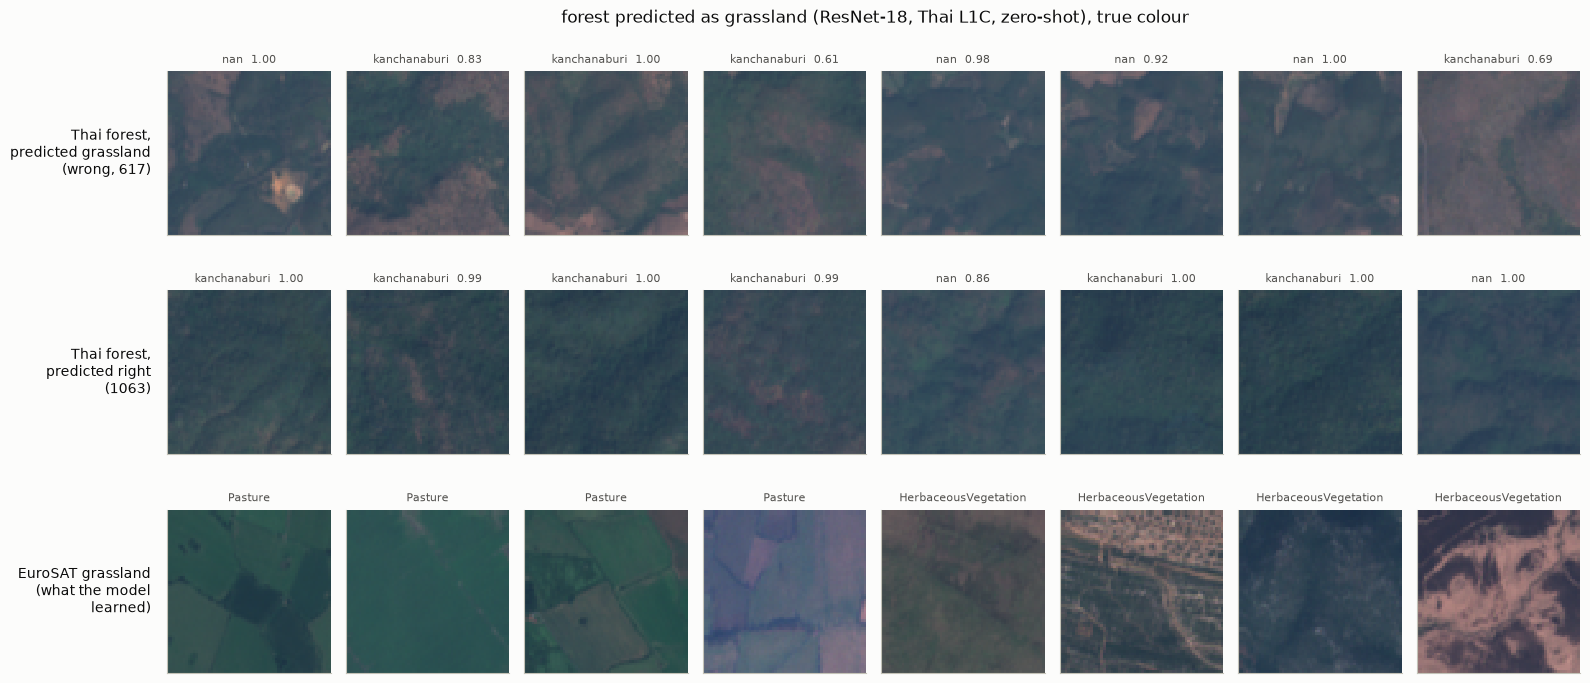

In [8]:
example_figure("forest", "grassland", ["Pasture", "HerbaceousVegetation"], ["kanchanaburi", "nan"], "examples_forest_as_grassland.png")

### 3.2 crop -> grassland

saved C:\Users\kanoo\Data_Mining_Project\outputs\a7\examples_crop_as_grassland.png


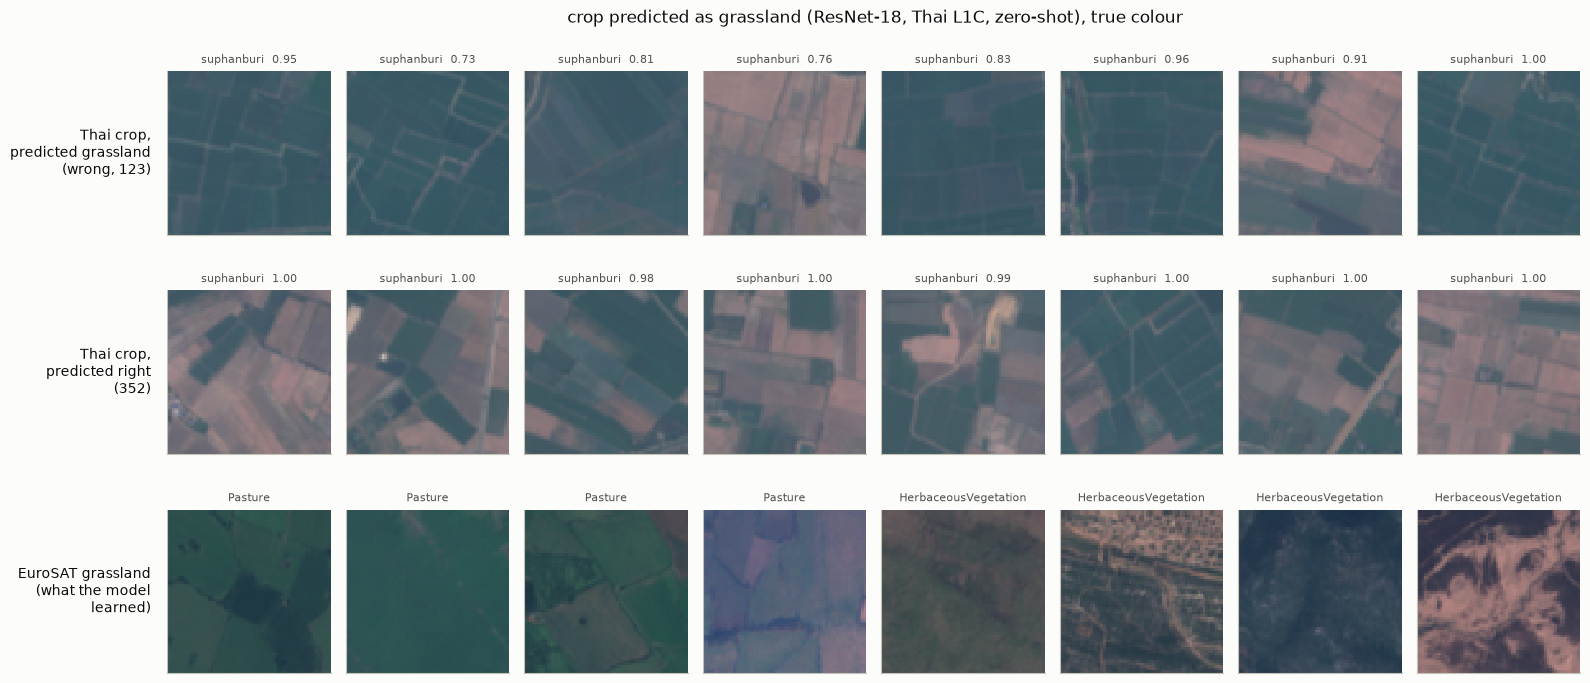

In [9]:
example_figure("crop", "grassland", ["Pasture", "HerbaceousVegetation"], ["suphanburi"], "examples_crop_as_grassland.png")

### 3.3 forest -> crop

saved C:\Users\kanoo\Data_Mining_Project\outputs\a7\examples_forest_as_crop.png


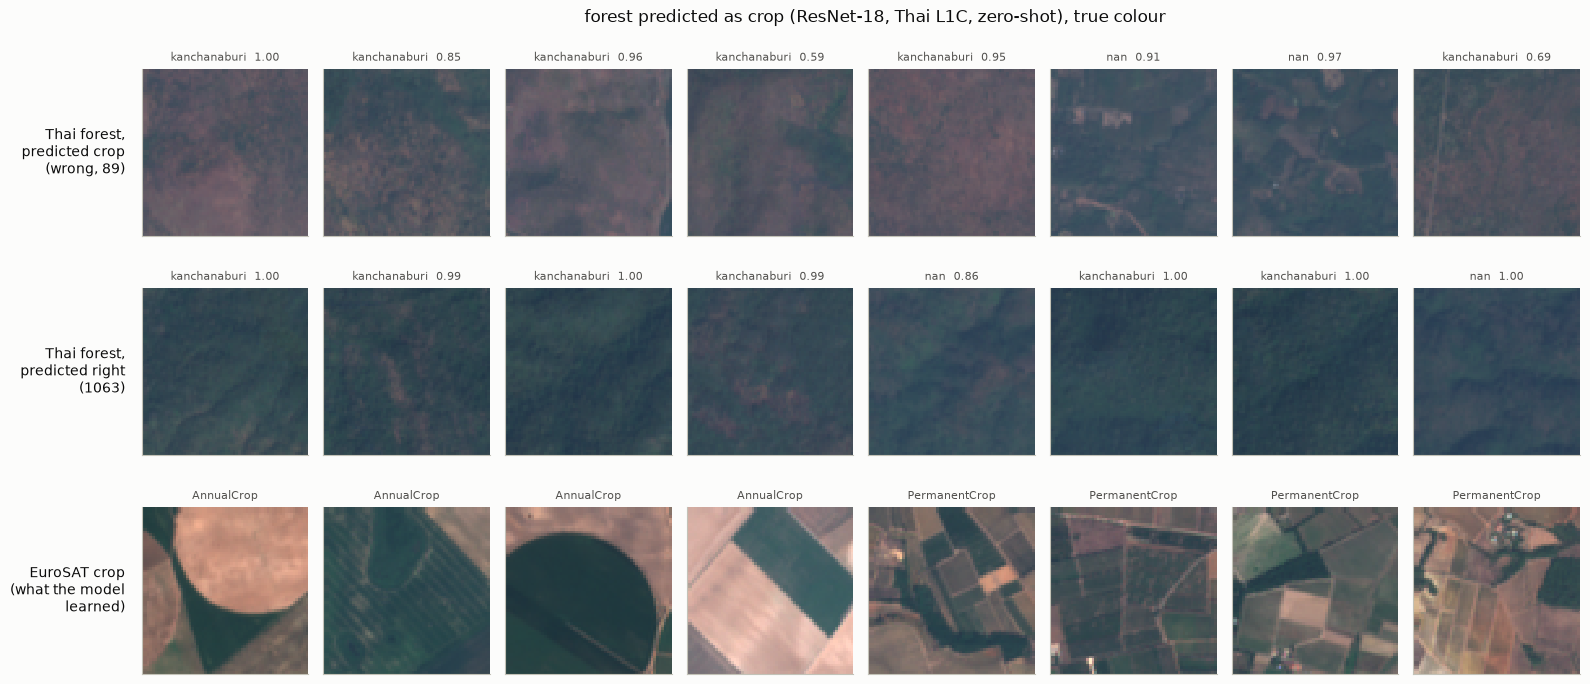

In [10]:
example_figure("forest", "crop", ["AnnualCrop", "PermanentCrop"], ["kanchanaburi", "nan"], "examples_forest_as_crop.png")

### 3.4 crop -> built-up

saved C:\Users\kanoo\Data_Mining_Project\outputs\a7\examples_crop_as_built-up.png


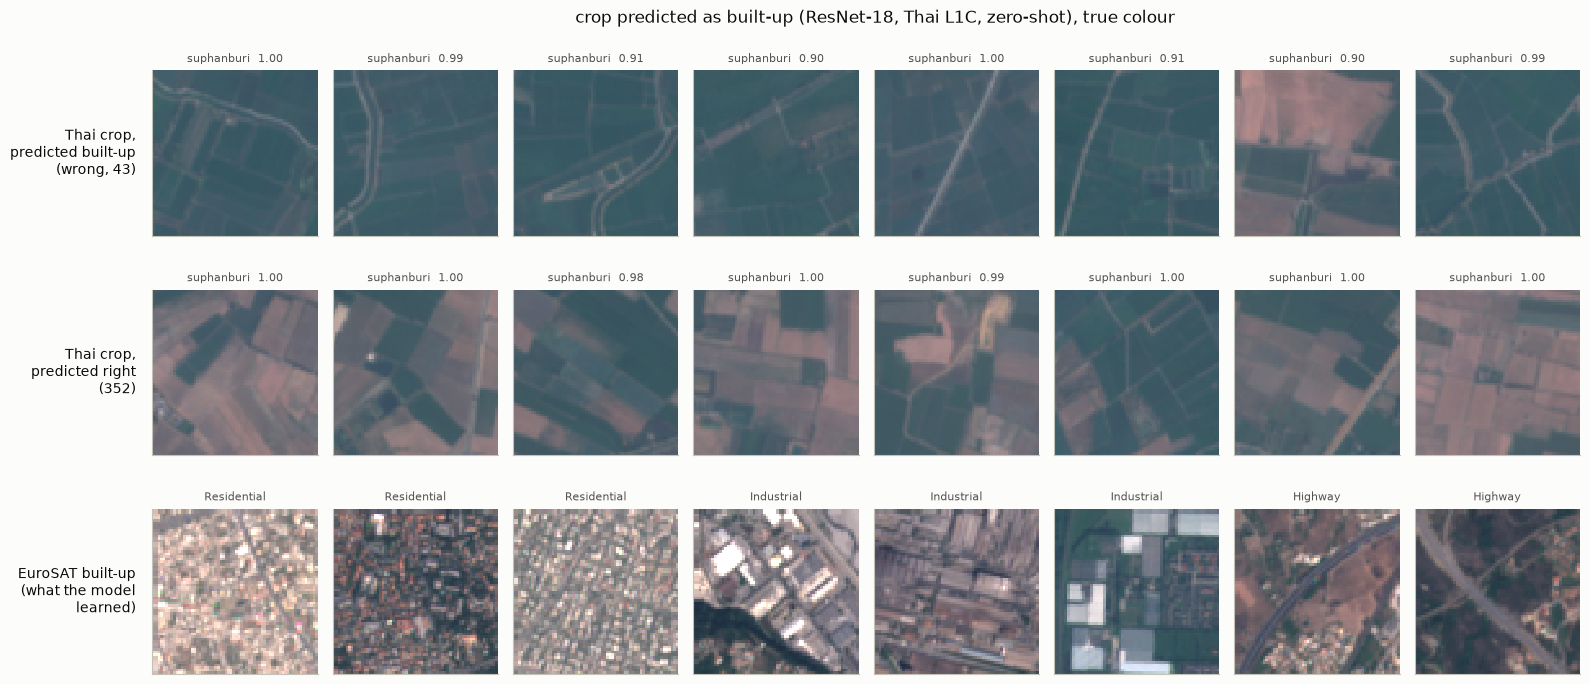

In [11]:
example_figure("crop", "built-up", ["Residential", "Industrial", "Highway"], ["suphanburi"], "examples_crop_as_built-up.png")

## 4. Testing explanations with numbers

The pictures suggest explanations; this section checks them on all patches, not only the eight shown. For every patch the mean over its
4,096 pixels is taken of NDVI (`(B8 - B4) / (B8 + B4)`, how green), red (B4) and short-wave infrared (B11, B12; high for dry
vegetation, bare soil and roofs, low for moist green leaves). EuroSAT reference values come from 400 random training patches of each original class.

To measure how well one number tells the wrong patches from the right ones inside a class, the **AUC** is given:
0.5 means the number does not separate them at all, 1.0 means it separates them perfectly.

In [12]:
def patch_means(X, ids, step=500):
    ndvi, bands = [], []
    for i in range(0, len(ids), step):
        block = np.asarray(X[np.sort(ids[i:i + step])], dtype="float32")
        order = np.argsort(np.argsort(ids[i:i + step]))       # back to the order of ids
        block = block[order]
        b8, b4 = block[:, c.BANDS.index("B8")], block[:, c.BANDS.index("B4")]
        ndvi.append(((b8 - b4) / np.maximum(b8 + b4, 1)).mean(axis=(1, 2)))
        bands.append(block.mean(axis=(2, 3)))
    return np.concatenate(ndvi), np.concatenate(bands)


FEATURES = ["NDVI", "B4", "B8", "B11", "B12"]
nd, bm = patch_means(X_TH, df.index.to_numpy())
df["NDVI"] = nd
for b in FEATURES[1:]:
    df[b] = bm[:, c.BANDS.index(b)]

rng = np.random.default_rng(c.SEED)
eu_rows = []
for name in ["Forest", "Pasture", "HerbaceousVegetation", "AnnualCrop", "PermanentCrop"]:
    pool = np.flatnonzero((EU_Y10 == c.EUROSAT_CLASSES.index(name)) & (EU_SPLIT == 0))
    nd, bm = patch_means(X_EU, rng.choice(pool, 400, replace=False))
    eu_rows.append(pd.DataFrame({"group": f"EuroSAT {name}", "NDVI": nd, **{b: bm[:, c.BANDS.index(b)] for b in FEATURES[1:]}}))
eu = pd.concat(eu_rows, ignore_index=True)

df[["area", "label", "purity", "zs", "zs_conf", "adabn", "adabn_conf", "wrong_in_all_seeds"] + FEATURES].round(4).to_csv(OUT / "patch_features.csv")

In [13]:
sel = df[df["label"].isin(["forest", "crop"]) & df["zs"].isin(["forest", "crop", "grassland", "built-up"])]
sel = sel[sel["area"].isin(["kanchanaburi", "nan", "suphanburi"])]
table = sel.groupby(["label", "area", "zs"])[FEATURES].median()
table.insert(0, "patches", sel.groupby(["label", "area", "zs"]).size())
eu_table = eu.groupby("group")[FEATURES].median()
eu_table.insert(0, "patches", eu.groupby("group").size())
medians = pd.concat([table.reset_index().assign(group=lambda t: "Thai " + t["label"] + " " + t["area"] + ", predicted " + t["zs"])
                     .set_index("group")[["patches"] + FEATURES], eu_table])
medians.round(3).to_csv(OUT / "feature_medians.csv")
medians.round(3)

,patches,NDVI,B4,B8,B11,B12
group,,,,,,
"Thai crop kanchanaburi, predicted crop",1,0.242,1202.152954,1995.078003,2630.924072,1732.262939
"Thai crop nan, predicted crop",4,0.356,1234.715942,2458.093018,2645.648926,1652.031982
"Thai crop nan, predicted grassland",9,0.305,1097.031982,2133.362061,1794.407959,1013.213013
"Thai crop suphanburi, predicted built-up",43,0.492,788.947021,2587.689941,1669.182007,802.312012
"Thai crop suphanburi, predicted crop",352,0.443,895.547974,2484.531006,1816.525024,956.911987
"Thai crop suphanburi, predicted forest",1,0.645,682.291992,3190.136963,1622.468018,723.614990
"Thai crop suphanburi, predicted grassland",123,0.534,762.838989,2611.479004,1628.770020,769.190979
"Thai forest kanchanaburi, predicted crop",48,0.343,1004.879028,2058.842041,2079.467041,1160.836060
"Thai forest kanchanaburi, predicted forest",700,0.585,602.086975,2341.479004,1581.150024,690.966980


In [14]:
rows = []
for cls, pred in [("forest", "grassland"), ("forest", "crop"), ("crop", "grassland"), ("crop", "built-up")]:
    d = df[(df["label"] == cls) & (df["zs_ok"] | (df["zs"] == pred))]
    y = (d["zs"] == pred).astype(int)
    for f in FEATURES:
        auc = roc_auc_score(y, d[f])
        rows.append({"mistake": f"{cls} -> {pred}", "feature": f, "AUC": round(max(auc, 1 - auc), 3),
                     "wrong patches have": "higher" if auc > 0.5 else "lower"})
auc = pd.DataFrame(rows).pivot(index="mistake", columns="feature", values=["AUC", "wrong patches have"])
auc.to_csv(OUT / "feature_auc.csv")
auc

AUC                             wrong patches have  \
feature                B11    B12     B4     B8   NDVI                B11   
mistake                                                                     
crop -> built-up     0.575  0.567  0.552  0.556  0.552              lower   
crop -> grassland    0.612   0.62  0.595   0.59  0.584              lower   
forest -> crop       0.987  0.997  0.995  0.662  0.941             higher   
forest -> grassland  0.949  0.967   0.96  0.576  0.881             higher   

                                                     
feature                 B12      B4      B8    NDVI  
mistake                                              
crop -> built-up      lower   lower  higher  higher  
crop -> grassland     lower   lower  higher  higher  
forest -> crop       higher  higher   lower   lower  
forest -> grassland  higher  higher   lower   lower

### Figure: NDVI and short-wave infrared of right and wrong patches

Each box is one group of patches (box: middle half, line: median). Thai groups are orange, EuroSAT reference classes blue.

saved C:\Users\kanoo\Data_Mining_Project\outputs\a7\ndvi_swir_right_vs_wrong.png


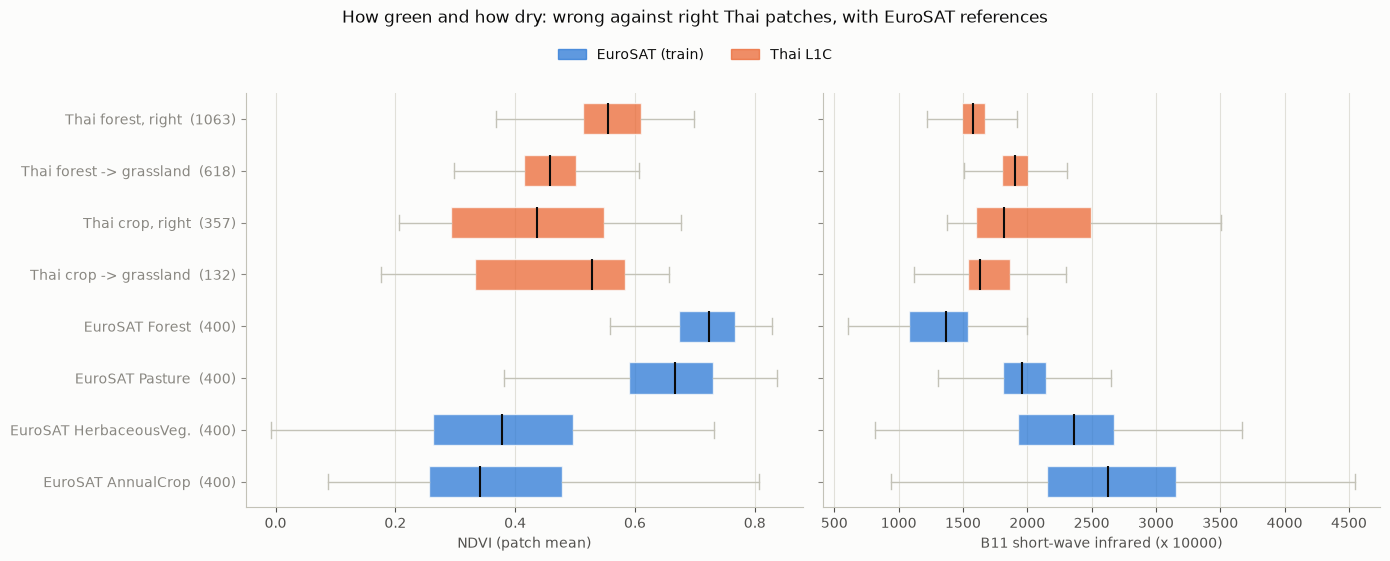

In [15]:
groups = [
    ("Thai forest, right", df[(df["label"] == "forest") & df["zs_ok"]], "Thai L1C"),
    ("Thai forest -> grassland", df[(df["label"] == "forest") & (df["zs"] == "grassland")], "Thai L1C"),
    ("Thai crop, right", df[(df["label"] == "crop") & df["zs_ok"]], "Thai L1C"),
    ("Thai crop -> grassland", df[(df["label"] == "crop") & (df["zs"] == "grassland")], "Thai L1C"),
    ("EuroSAT Forest", eu[eu["group"] == "EuroSAT Forest"], "EuroSAT (train)"),
    ("EuroSAT Pasture", eu[eu["group"] == "EuroSAT Pasture"], "EuroSAT (train)"),
    ("EuroSAT HerbaceousVeg.", eu[eu["group"] == "EuroSAT HerbaceousVegetation"], "EuroSAT (train)"),
    ("EuroSAT AnnualCrop", eu[eu["group"] == "EuroSAT AnnualCrop"], "EuroSAT (train)"),
]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, feature, label in [(axes[0], "NDVI", "NDVI (patch mean)"), (axes[1], "B11", "B11 short-wave infrared (x 10000)")]:
    data = [g[feature].to_numpy() for _, g, _ in groups]
    box = ax.boxplot(data, orientation="horizontal", patch_artist=True, widths=0.6, showfliers=False,
                     medianprops={"color": INK, "linewidth": 1.5}, whiskerprops={"color": AXIS}, capprops={"color": AXIS})
    for patch, (_, _, src) in zip(box["boxes"], groups):
        patch.set_facecolor(SOURCE_COLORS[src])
        patch.set_alpha(0.75)
        patch.set_edgecolor(SURFACE)
    ax.set_yticks(range(1, len(groups) + 1))
    ax.set_yticklabels([f"{n}  ({len(g)})" for n, g, _ in groups])
    ax.invert_yaxis()
    ax.grid(axis="x", visible=True)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(label)
axes[1].set_yticklabels([])
fig.legend(handles=[Patch(color=col, alpha=0.75, label=name) for name, col in SOURCE_COLORS.items()],
           loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("How green and how dry: wrong against right Thai patches, with EuroSAT references", y=1.07, fontsize=12, color=INK)
fig.tight_layout()
save(fig, "ndvi_swir_right_vs_wrong.png")
plt.show()

## 5. Where the mistakes are on the ground

Each study area is a grid of 48 x 48 patches. Left: the area in true colour. Right: every pure patch, grey when the zero-shot model is right,
coloured by the **predicted** class when it is wrong. Patches that are not pure are left blank (they are not tested).

saved C:\Users\kanoo\Data_Mining_Project\outputs\a7\error_maps.png


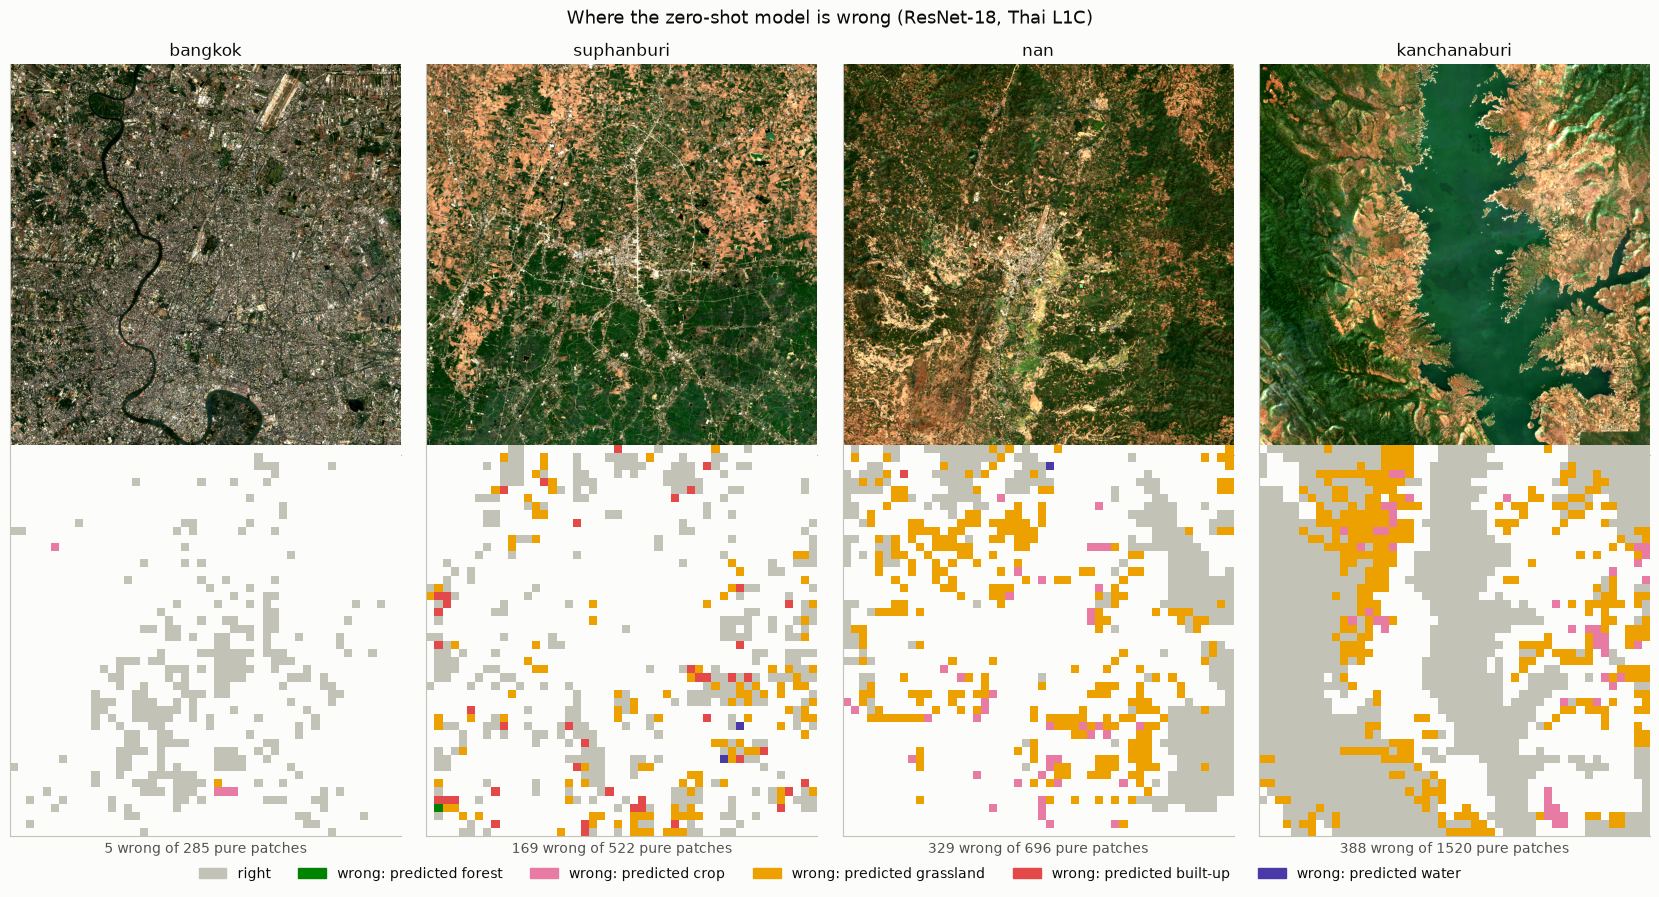

In [16]:
def area_rgb(area, size=768):
    with rasterio.open(c.thai_path(area, "S2_L2A.tif")) as src:
        names = list(src.descriptions)
        img = src.read([names.index(b) + 1 for b in ("B4", "B3", "B2")], out_shape=(3, size, size)).astype("float32")
    lo, hi = np.percentile(img[img > 0], (2, 98))
    return np.clip((img.transpose(1, 2, 0) - lo) / (hi - lo), 0, 1)


codes = {"blank": 0, "right": 1, "forest": 2, "crop": 3, "grassland": 4, "built-up": 5, "water": 6}
cmap = ListedColormap([SURFACE, AXIS, CLASS_COLORS["forest"], CLASS_COLORS["crop"], CLASS_COLORS["grassland"],
                       CLASS_COLORS["built-up"], CLASS_COLORS["water"]])
areas = list(c.AOIS)
fig, axes = plt.subplots(2, len(areas), figsize=(4.2 * len(areas), 8.8))
for k, area in enumerate(areas):
    grid = np.zeros((48, 48), dtype=int)
    part = df[df["area"] == area]
    for (_, r) in part.iterrows():
        grid[r["row"], r["col"]] = codes["right"] if r["zs_ok"] else codes[r["zs"]]
    axes[0, k].imshow(area_rgb(area))
    axes[0, k].set_title(area, fontsize=12, color=INK)
    axes[1, k].imshow(grid, cmap=cmap, vmin=0, vmax=len(codes) - 1, interpolation="nearest")
    wrong, total = int((~part["zs_ok"]).sum()), len(part)
    axes[1, k].set_xlabel(f"{wrong} wrong of {total} pure patches", fontsize=10, color=INK2)
    for ax in axes[:, k]:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
legend = [Patch(color=AXIS, label="right")] + [Patch(color=CLASS_COLORS[n], label=f"wrong: predicted {n}")
                                               for n in ["forest", "crop", "grassland", "built-up", "water"]]
fig.legend(handles=legend, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
fig.suptitle("Where the zero-shot model is wrong (ResNet-18, Thai L1C)", fontsize=13, color=INK, y=0.995)
save(fig, "error_maps.png")
plt.show()

## 6. How sure is the model when it is wrong, and does the mistake repeat

A model that is unsure when it is wrong could at least warn the user. The left panel compares the confidence (probability of the predicted class)
of right and wrong predictions. The table counts mistakes that all three trained models (seeds 42, 1, 2) make on the same patch: those come from the
data, not from the chance of one training run.

saved C:\Users\kanoo\Data_Mining_Project\outputs\a7\confidence_right_vs_wrong.png


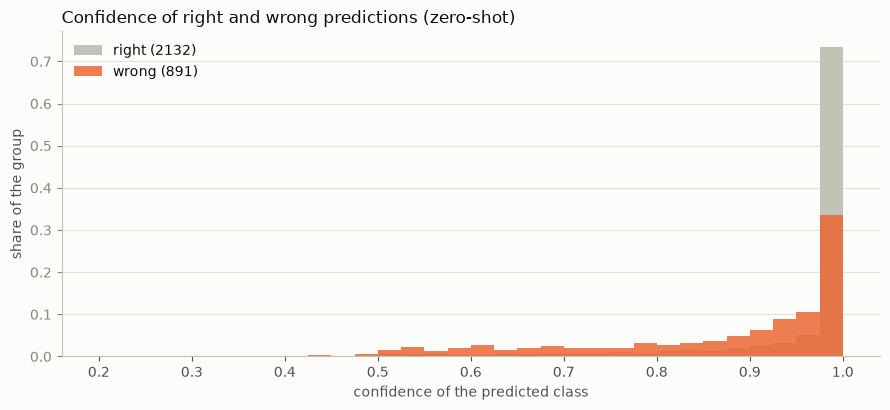

wrong predictions with confidence above 0.95: 393 of 891 (44%); right ones: 79%

patches wrong in all three seeds: 743 (wrong in at least one seed: 1240)


wrong in all 3 seeds
label  zs                             
crop   built-up                     33
       grassland                    79
forest built-up                      1
       crop                         91
       grassland                   538
       water                         1

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.linspace(0.2, 1.0, 33)
for name, part, col in [("right", df[df["zs_ok"]], AXIS), ("wrong", df[~df["zs_ok"]], RUN_COLORS["zero-shot"])]:
    ax.hist(part["zs_conf"], bins=bins, color=col, alpha=0.85 if name == "wrong" else 1.0, label=f"{name} ({len(part)})",
            weights=np.full(len(part), 1 / len(part)))
ax.set_xlabel("confidence of the predicted class")
ax.set_ylabel("share of the group")
ax.set_title("Confidence of right and wrong predictions (zero-shot)", loc="left", fontsize=12, color=INK)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
save(fig, "confidence_right_vs_wrong.png")
plt.show()

wrong = df[~df["zs_ok"]]
print(f"wrong predictions with confidence above 0.95: {(wrong['zs_conf'] > 0.95).sum()} of {len(wrong)} "
      f"({(wrong['zs_conf'] > 0.95).mean():.0%}); right ones: {(df[df['zs_ok']]['zs_conf'] > 0.95).mean():.0%}")
repeat = df[df["wrong_in_all_seeds"]].groupby(["label", "zs"]).size().rename("wrong in all 3 seeds")
print(f"\npatches wrong in all three seeds: {df['wrong_in_all_seeds'].sum()} "
      f"(wrong in at least one seed: {(~df['zs_ok'] | ~df['s1_ok'] | ~df['s2_ok']).sum()})")
repeat.to_frame()

## 7. Model mistake or label mistake? The hand-labelled patches

WorldCover is a model too, so a "wrong" prediction could be a wrong WorldCover label. The 199 hand-labelled patches of step A1 (vote of three people)
check this: where the model disagrees with WorldCover, do the people side with the model or with WorldCover?

In [18]:
clean = pd.read_csv(c.OUTPUT_DIR / "a1" / "clean_test_set.csv").set_index("patch_id")
clean = clean.join(df[["zs", "adabn"]])
disagree = clean[clean["zs"] != clean["worldcover"]]
side = pd.Series({
    "people agree with WorldCover": int((disagree["consensus"] == disagree["worldcover"]).sum()),
    "people agree with the model": int((disagree["consensus"] == disagree["zs"]).sum()),
    "people agree with neither": int(((disagree["consensus"] != disagree["worldcover"]) & (disagree["consensus"] != disagree["zs"])).sum()),
}, name=f"zero-shot model disagrees with WorldCover on {len(disagree)} of {len(clean)} hand-labelled patches")
print(side.to_string(), "\n")
print("patches where people and WorldCover disagree, and what the models say:")
clean.loc[clean["consensus"] != clean["worldcover"], ["consensus", "worldcover", "zs", "adabn"]]

people agree with WorldCover    41
people agree with the model      1
people agree with neither        3 

patches where people and WorldCover disagree, and what the models say:


,consensus,worldcover,zs,adabn
patch_id,,,,
5296,crop,forest,grassland,grassland
5646,crop,forest,crop,grassland
5695,crop,forest,grassland,grassland
6407,forest,crop,grassland,crop


## 8. Findings

The findings with their numbers are written up in `outputs/a7/summary.md` (made after running this notebook), together with what is
measured and what is only a likely explanation.